# Comparaison finale des modèles : protocoles `daily` et `temporal`

Le sujet, les données et leur preprocessing, les protocoles et les métriques sont présentés dans `introduction.ipynb`.

Chaque membre du groupe a choisi les réglages d'une famille de modèles par validation croisée, dans son propre notebook. Ce notebook **ne règle plus rien** : il reprend ces réglages tels quels et compare tous les modèles **dans les mêmes conditions**, avec un seul tableau calculé par le code.

On répond à deux questions :
1. **Quel modèle est le meilleur ?** (protocole `daily` : prédire des jours manquants, toutes saisons connues)
2. **Ce classement tient-il quand on prédit le futur ?** (protocole `temporal` : apprendre jusqu'au 10/09/2018, puis prédire l'automne semaine par semaine, en réentraînant chaque semaine avec le passé disponible)

| Modèle | Notebook d'origine | Réglages retenus |
|---|---|---|
| Référence naïve | (ce notebook) | moyenne de la demande par heure et par type de jour |
| Linéaire : variables + polynôme degré 2 + Ridge | `regression_lineaire.ipynb` | α = 1000 |
| Forêt aléatoire | `modeles_arbres.ipynb` | 200 arbres, profondeur 20, min_samples_split = 4 |
| XGBoost réglé | `tuning_xgboost.ipynb` | profondeur 6, pas 0,04, 500 arbres, subsample 0,75, colsample 0,75, min_child_weight 3, λ = 2 |
| Réseau de neurones (MLP) | `reseau_neurones.ipynb` | couches (64, 32), α = 0,1 |

**Règle** : le test n'a servi à aucun de ces choix. Ici on le regarde une seule fois.


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

from decoupage import (charger_donnees, decoupage_daily, decoupage_temporal,
                       walk_forward, variables, CIBLE)

donnees = charger_donnees()
print(f"{len(donnees)} heures, {donnees['date'].nunique()} jours")

8465 heures, 353 jours


## 1. Les modèles

### La référence naïve

Avant tout modèle, on se demande : *que ferait quelqu'un sans machine learning ?* Il regarderait la demande moyenne **à cette heure-là, un jour de semaine ou un jour off** (week-end ou férié). Cette référence connaît déjà le double pic 8 h / 18 h ; un modèle qui ne la bat pas nettement n'apporte rien.

In [2]:
class MoyenneParHeure(BaseEstimator, RegressorMixin):
    # Prédit la demande moyenne observée à la même heure, pour le même type de jour (travaillé ou off)
    def _cles(self, X):
        jour_off = ((X["is_weekend"] == 1) | (X["holiday"] == 1)).astype(int)
        return list(zip(X["hour"], jour_off))

    def fit(self, X, y):
        self.moyennes_ = pd.Series(np.asarray(y), index=pd.MultiIndex.from_tuples(self._cles(X))).groupby(level=[0, 1]).mean()
        self.moyenne_globale_ = float(np.mean(y))
        return self

    def predict(self, X):
        return np.array([self.moyennes_.get(c, self.moyenne_globale_) for c in self._cles(X)])

### Le modèle linéaire final

On reprend exactement le modèle 5 de `regression_lineaire.ipynb` : on ajoute une colonne par heure, une colonne par heure pour les jours off et des tranches de température de 4 °C, puis toutes les combinaisons de degré 2, freinées par Ridge (α = 1000).

La fonction `feature_engineering` est placée **dans le pipeline** (`FunctionTransformer`) : elle est appliquée de la même façon à chaque jeu de données. Les colonnes d'heures sont créées explicitement de 0 à 23, pour qu'une semaine où une heure manque ait quand même les mêmes colonnes.

In [3]:
def feature_engineering(X):
    X = X.copy()
    jour_off = ((X["is_weekend"] == 1) | (X["holiday"] == 1)).astype(int)
    nouvelles = {}
    for h in range(24):
        heure_h = (X["hour"] == h).astype(int)
        nouvelles[f"heure_{h}"] = heure_h
        nouvelles[f"heure_{h}_off"] = heure_h * jour_off
    tranches = pd.cut(X["temperature"], bins=range(-20, 45, 4))
    for t in tranches.cat.categories:
        nouvelles[f"temp_{t}"] = (tranches == t).astype(int)
    return pd.concat([X, pd.DataFrame(nouvelles, index=X.index)], axis=1)


def creer_modeles():
    return {
        "Référence (moyenne par heure)": MoyenneParHeure(),
        "Linéaire (poly 2 + Ridge)": make_pipeline(
            FunctionTransformer(feature_engineering),
            PolynomialFeatures(2, include_bias=False),
            VarianceThreshold(1e-6),
            StandardScaler(),
            Ridge(alpha=1000),
        ),
        "Forêt aléatoire": RandomForestRegressor(
            n_estimators=200, max_depth=20, min_samples_split=4, random_state=42, n_jobs=-1),
        "XGBoost réglé": xgb.XGBRegressor(
            max_depth=6, learning_rate=0.04, n_estimators=500, subsample=0.75,
            colsample_bytree=0.75, min_child_weight=3, reg_lambda=2.0, gamma=0.0,
            random_state=42, n_jobs=-1),
        "Réseau de neurones": TransformedTargetRegressor(
            regressor=make_pipeline(StandardScaler(), MLPRegressor(
                hidden_layer_sizes=(64, 32), activation="relu", solver="adam", alpha=0.1,
                learning_rate_init=0.001, max_iter=500, random_state=42)),
            transformer=StandardScaler()),
    }


def scores(y_vrai, y_pred):
    return {"RMSE": root_mean_squared_error(y_vrai, y_pred),
            "MAE": mean_absolute_error(y_vrai, y_pred),
            "R²": r2_score(y_vrai, y_pred)}

list(creer_modeles())

['Référence (moyenne par heure)',
 'Linéaire (poly 2 + Ridge)',
 'Forêt aléatoire',
 'XGBoost réglé',
 'Réseau de neurones']

Une demande de vélos ne peut pas être négative : pour **tous** les modèles, on ramène les prédictions négatives à 0 (`np.clip`). C'est la même règle pour tout le monde, donc la comparaison reste juste.

## 2. Protocole `daily`

Chaque modèle est entraîné une fois sur les 283 jours d'entraînement, puis évalué sur les 70 jours de test (environ 6 par mois).

In [4]:
train_d, test_d = decoupage_daily(donnees)
X_train_d, y_train_d = train_d[variables(train_d)], train_d[CIBLE]
X_test_d, y_test_d = test_d[variables(test_d)], test_d[CIBLE]

resultats = []
predictions_daily = {}
for nom, modele in creer_modeles().items():
    debut = time.time()
    modele.fit(X_train_d, y_train_d)
    pred = np.clip(modele.predict(X_test_d), 0, None)
    predictions_daily[nom] = pred
    resultats.append({"Modèle": nom, "Protocole": "daily", **scores(y_test_d, pred)})
    print(f"{nom:<32} RMSE = {resultats[-1]['RMSE']:6.1f}   ({time.time() - debut:4.0f} s)")

Référence (moyenne par heure)    RMSE =  508.2   (   0 s)


Linéaire (poly 2 + Ridge)        RMSE =  202.4   (   1 s)


Forêt aléatoire                  RMSE =  190.1   (   1 s)


XGBoost réglé                    RMSE =  174.4   (   1 s)


Réseau de neurones               RMSE =  193.2   (   2 s)


## 3. Protocole `temporal` (walk-forward)

Pour chacune des 10 semaines de test (du 11/09 au 30/11/2018), on réentraîne le modèle sur **tout le passé disponible** puis on prédit la semaine. On calcule ensuite l'erreur sur l'ensemble des 10 semaines.

In [5]:
resultats = [r for r in resultats if r["Protocole"] != "temporal"]  # évite les doublons si la cellule est relancée
train_t, test_t = decoupage_temporal(donnees)
semaines = list(walk_forward(train_t, test_t))

predictions_temporal = []
for nom, modele in creer_modeles().items():
    debut = time.time()
    for numero, (passe, semaine) in enumerate(semaines, start=1):
        m = clone(modele).fit(passe[variables(passe)], passe[CIBLE])
        pred = np.clip(m.predict(semaine[variables(semaine)]), 0, None)
        predictions_temporal.append(pd.DataFrame({
            "Modèle": nom, "semaine": numero, "date": semaine["date"].values,
            "hour": semaine["hour"].values, "réel": semaine[CIBLE].values, "prédit": pred}))
    print(f"{nom:<32} terminé ({time.time() - debut:4.0f} s)")

predictions_temporal = pd.concat(predictions_temporal, ignore_index=True)
for nom, groupe in predictions_temporal.groupby("Modèle", sort=False):
    resultats.append({"Modèle": nom, "Protocole": "temporal", **scores(groupe["réel"], groupe["prédit"])})

Référence (moyenne par heure)    terminé (   0 s)


Linéaire (poly 2 + Ridge)        terminé (  11 s)


Forêt aléatoire                  terminé (   9 s)


XGBoost réglé                    terminé (  10 s)


Réseau de neurones               terminé (  21 s)


## 4. Le tableau final

In [6]:
resultats = pd.DataFrame(resultats).drop_duplicates(["Modèle", "Protocole"], keep="last").to_dict("records")
tableau = pd.DataFrame(resultats).pivot(index="Modèle", columns="Protocole", values=["RMSE", "MAE", "R²"])
tableau = tableau.loc[list(creer_modeles())]
tableau[("Écart RMSE", "temporal / daily")] = (tableau[("RMSE", "temporal")] / tableau[("RMSE", "daily")] - 1) * 100
tableau.round({("RMSE", "daily"): 1, ("RMSE", "temporal"): 1, ("MAE", "daily"): 1, ("MAE", "temporal"): 1,
               ("R²", "daily"): 3, ("R²", "temporal"): 3, ("Écart RMSE", "temporal / daily"): 0})

RMSE             MAE              R²           \
Protocole                      daily temporal  daily temporal  daily temporal   
Modèle                                                                          
Référence (moyenne par heure)  508.2    424.2  399.9    306.8  0.354    0.498   
Linéaire (poly 2 + Ridge)      202.4    239.9  125.5    159.6  0.898    0.840   
Forêt aléatoire                190.1    242.8  112.1    158.8  0.910    0.836   
XGBoost réglé                  174.4    221.4  102.5    140.2  0.924    0.863   
Réseau de neurones             193.2    218.0  119.5    146.5  0.907    0.868   

                                    Écart RMSE  
Protocole                     temporal / daily  
Modèle                                          
Référence (moyenne par heure)            -17.0  
Linéaire (poly 2 + Ridge)                 19.0  
Forêt aléatoire                           28.0  
XGBoost réglé                             27.0  
Réseau de neurones                        13.0

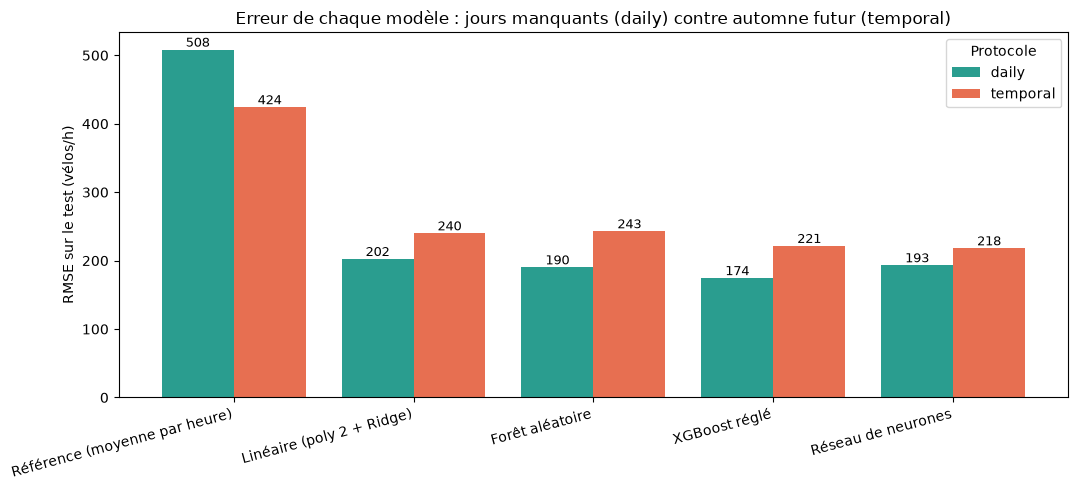

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
noms = list(tableau.index)
x = np.arange(len(noms))
for decalage, protocole, couleur in [(-0.2, "daily", "#2a9d8f"), (0.2, "temporal", "#e76f51")]:
    valeurs = tableau[("RMSE", protocole)].values
    barres = ax.bar(x + decalage, valeurs, width=0.4, label=protocole, color=couleur)
    ax.bar_label(barres, fmt="%.0f", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(noms, rotation=15, ha="right")
ax.set_ylabel("RMSE sur le test (vélos/h)")
ax.set_title("Erreur de chaque modèle : jours manquants (daily) contre automne futur (temporal)")
ax.legend(title="Protocole")
plt.tight_layout()
plt.show()

## 5. Où se trompent-ils en `temporal` ? Semaine par semaine

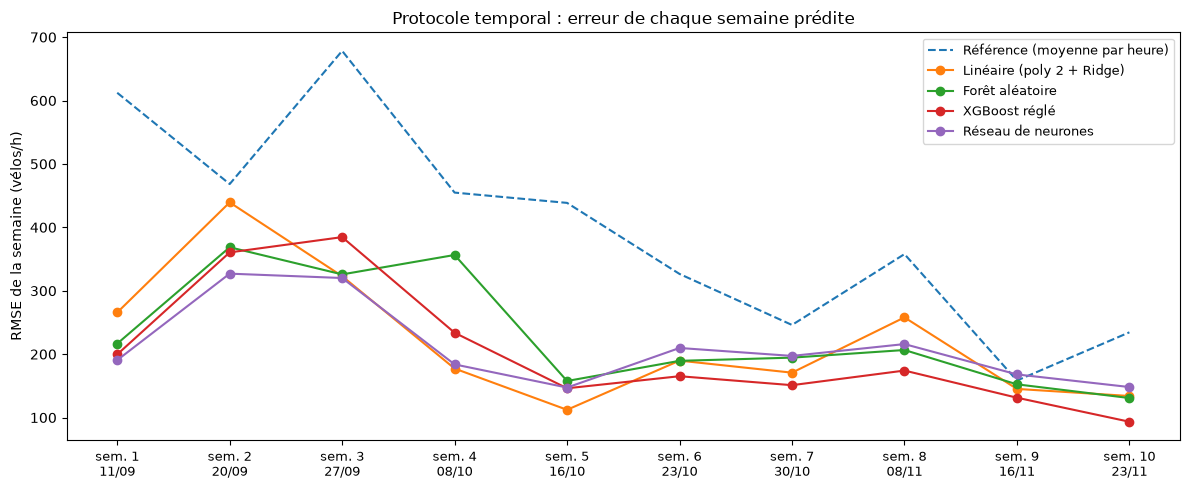

semaine,1,2,3,4,5,6,7,8,9,10
Modèle,,,,,,,,,,
Référence (moyenne par heure),612.0,468.0,678.0,455.0,439.0,327.0,246.0,358.0,158.0,234.0
Linéaire (poly 2 + Ridge),266.0,439.0,323.0,177.0,112.0,190.0,171.0,258.0,145.0,134.0
Forêt aléatoire,217.0,369.0,326.0,356.0,158.0,189.0,195.0,207.0,152.0,131.0
XGBoost réglé,200.0,361.0,385.0,234.0,146.0,165.0,151.0,174.0,131.0,93.0
Réseau de neurones,191.0,327.0,320.0,184.0,147.0,210.0,197.0,216.0,168.0,148.0


In [8]:
rmse_semaine = (predictions_temporal.groupby(["Modèle", "semaine"], sort=False)
                .apply(lambda g: root_mean_squared_error(g["réel"], g["prédit"]))
                .unstack(0)[list(creer_modeles())])
debuts = predictions_temporal.groupby("semaine")["date"].min().dt.strftime("%d/%m")

fig, ax = plt.subplots(figsize=(12, 5))
for nom in rmse_semaine.columns:
    style = "--" if nom.startswith("Référence") else "o-"
    ax.plot(rmse_semaine.index, rmse_semaine[nom], style, label=nom)
ax.set_xticks(rmse_semaine.index)
ax.set_xticklabels([f"sem. {s}\n{debuts[s]}" for s in rmse_semaine.index], fontsize=9)
ax.set_ylabel("RMSE de la semaine (vélos/h)")
ax.set_title("Protocole temporal : erreur de chaque semaine prédite")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

rmse_semaine.round(0).T

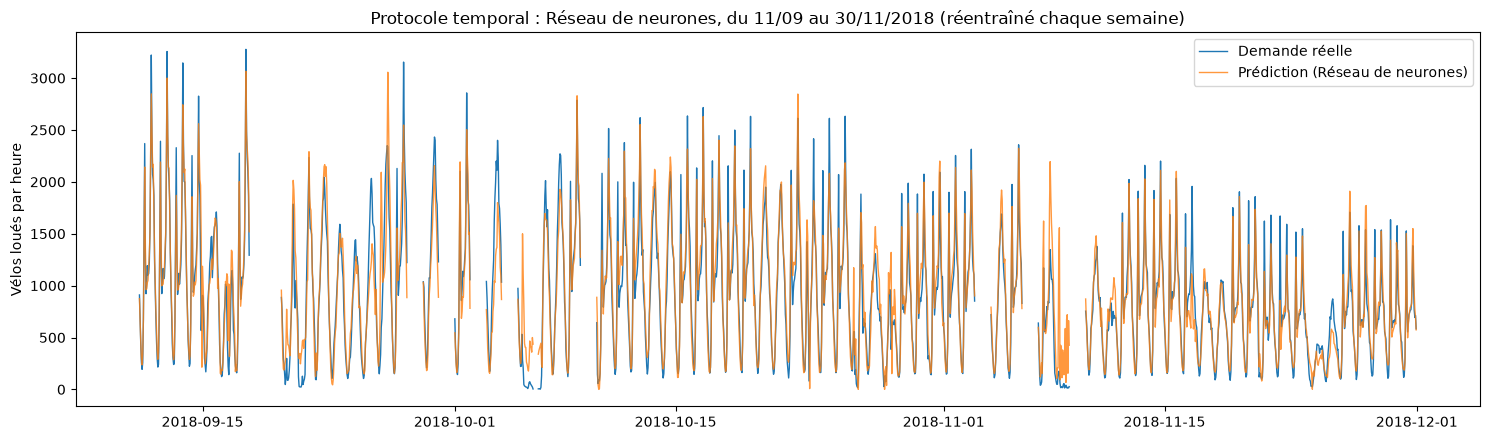

In [9]:
# Le meilleur modèle en temporal : réel et prédit sur tout l'automne
meilleur_t = tableau[("RMSE", "temporal")].idxmin()
serie = predictions_temporal[predictions_temporal["Modèle"] == meilleur_t].copy()
serie["instant"] = pd.to_datetime(serie["date"]) + pd.to_timedelta(serie["hour"], unit="h")
serie = serie.set_index("instant").sort_index()
serie = serie.reindex(pd.date_range(serie.index.min(), serie.index.max(), freq="h"))  # trous = service fermé

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(serie.index, serie["réel"], label="Demande réelle", linewidth=1)
ax.plot(serie.index, serie["prédit"], label=f"Prédiction ({meilleur_t})", linewidth=1, alpha=0.8)
ax.set_ylabel("Vélos loués par heure")
ax.set_title(f"Protocole temporal : {meilleur_t}, du 11/09 au 30/11/2018 (réentraîné chaque semaine)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Analyse

### Le classement change selon la question posée

| | Meilleur modèle | RMSE | R² |
|---|---|---|---|
| `daily` (jours manquants) | XGBoost réglé | 174 | 0,92 |
| `temporal` (automne futur) | Réseau de neurones | 218 | 0,87 |

- **En `daily`**, les arbres boostés gagnent : XGBoost (174) devant la forêt (190), le réseau (193) et le linéaire (202). Tous divisent l'erreur de la référence par 2,5 à 3.
- **En `temporal`**, tous les modèles se dégradent, mais **pas autant** : le réseau perd 13 %, le linéaire 19 %, XGBoost 27 % et la forêt 28 %. Le réseau (218) et XGBoost (221) arrivent en tête, presque à égalité ; le linéaire (240) et la forêt (243) suivent.

### Pourquoi les arbres perdent le plus

Un arbre (et donc une forêt ou XGBoost) prédit toujours une **moyenne de situations déjà vues** : il découpe l'espace en cases et renvoie la moyenne de chaque case. En `daily`, chaque mois est représenté à l'entraînement, donc chaque situation du test ressemble à une case connue. En `temporal`, le modèle n'a jamais vu d'automne : la combinaison « 12 °C, octobre, après l'été » tombe dans des cases apprises en mars ou en avril, où la demande était différente. Il **ne peut pas extrapoler**. Le réseau et le modèle linéaire produisent des fonctions continues de la température et de l'heure, qu'ils peuvent prolonger vers des situations nouvelles.

### Les semaines difficiles ont une explication

Les plus grosses erreurs, pour presque tous les modèles, tombent en **semaines 2 et 3** (20/09 au 07/10) :
- **semaine 2** : le Chuseok (23 au 25/09, grand congé coréen) arrive juste après deux jours de pluie. Les modèles n'ont vu qu'une poignée de jours fériés de ce type ;
- **semaine 3** : le 05/10 est un jour de très forte pluie (35 mm), avec une demande moyenne de 188 vélos/h contre plus de 1 000 les jours voisins. Or la winsorisation du prétraitement plafonne la pluie à 4 mm/h : le modèle ne voit pas à quel point ce jour était extrême. C'est un argument concret pour **ne pas winsoriser la pluie**.

À partir de la semaine 5, les erreurs redescendent nettement pour tous les modèles : à chaque réentraînement, le modèle intègre les premières semaines d'automne. C'est l'intérêt du réentraînement hebdomadaire.

Détail révélateur : **l'avantage du réseau vient des semaines 1 à 3**, quand l'automne est encore inconnu. À partir de la semaine 6, XGBoost est le meilleur chaque semaine (93 vélos/h en semaine 10) : dès que les arbres ont vu quelques semaines d'automne, leur problème d'extrapolation disparaît. Cela confirme l'explication ci-dessus.

### Pourquoi la référence semble « meilleure » en `temporal`

Sa RMSE baisse (508 → 424) et son R² monte (0,35 → 0,50). Ce n'est pas qu'elle devient bonne : la demande d'automne varie moins que celle de l'année entière (pas de saut hiver/été), donc une moyenne par heure s'en sort mieux. **On ne compare donc pas les R² d'un protocole à l'autre**, seulement les modèles entre eux à protocole égal.

### Limites de cette comparaison

- Les réglages de chaque modèle ont été choisis en `daily`, puis réutilisés tels quels en `temporal`.
- Le test `temporal` ne contient que 10 semaines, et les écarts entre le réseau et XGBoost (218 et 221), ou entre le linéaire et la forêt (240 et 243), sont plus petits que les écarts d'une semaine à l'autre : on ne peut pas les départager. Ce qui ressort, c'est que le réseau se dégrade le moins ; c'est à confirmer sur une autre année.
- Les modèles utilisent la **météo observée** de l'heure prédite. En situation réelle, l'opérateur n'aurait qu'une prévision météo, moins précise : les erreurs seraient plus grandes.

### Conclusion

**1. La demande de vélos est largement prévisible.**

Tous les modèles divisent l’erreur de la référence naïve par 2,5 à 3 (de 508 à environ 175-200 vélos/h en daily). Le calendrier et la météo de l’heure suffisent à expliquer environ 90 % des variations.

**2. Il n’y a pas un meilleur modèle, mais un meilleur modèle par usage.**

Pour reconstituer des jours manquants : XGBoost, 174 vélos/h, R² 0,92.
Pour prévoir une saison jamais vue : le réseau de neurones (218 vélos/h, R² 0,87) et XGBoost (221) sont au coude-à-coude. Le réseau est le meilleur sur les premières semaines d’automne ; les arbres ne savent pas extrapoler, mais après 5 à 6 semaines d’automne apprises, XGBoost redevient le meilleur.

**3. Un score ne vaut rien sans son protocole.** 

Le même XGBoost passe de 174 à 221 vélos/h (+27 %) selon le découpage. Annoncer « R² = 0,92 » sans préciser le protocole surestimerait ce qu’un opérateur obtiendrait en prévision.

**Recommandation pour l’opérateur :** réentraîner chaque semaine, et se méfier des modèles à arbres aux changements de saison. Pendant ces quelques semaines, le réseau est plus sûr.

**Perspectives :** utiliser des prévisions météo plutôt que la météo observée ; ne plus plafonner la pluie et mieux décrire les longs congés (Chuseok) ; tester une combinaison réseau + XGBoost ; valider sur une autre année.